## LBB Condition

The goal of this notebook is to review and play around with the LBB condition and the effects different function spaces have on the LBB condition and on the stiffness matrix. In which cases does it fail and in which cases is it stable and in which it isn't

In [2]:
from src.mesh_setup import generate_mesh
meshes = []
mesh_sizes = [1/4, 1/8, 1/16, 1/32]
for size in mesh_sizes:
    meshes.append(generate_mesh(size))

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000261502s, CPU 0.000306s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00132502s, CPU 0.001764s)
Info    : 31 nodes 64 elements
Info    : Done generating mesh
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000168458s, CPU 0.000207s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00283795s, CPU 0.00284s)
Info    : 98 nodes 198 elements
Info    : Done generating mesh
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info  

In [3]:
import numpy as np
import ufl
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.linalg as sla
from dolfinx import fem
from dolfinx.fem.petsc import assemble_matrix
from src.problem_builder import setup_problem


def to_scipy(M):
    indptr, indices, values = M.getValuesCSR()
    return sp.csr_matrix((values, indices, indptr), shape=M.getSize())


def lbb_blocks(mesh_data, v_degree, q_degree):
    """Velocity block A, divergence block B (with BCs) and pressure mass matrix Q."""
    a, L, bcs = setup_problem(mesh_data, "Lagrange", "Lagrange", v_degree, q_degree)
    Qspace = L[1].arguments()[0].ufl_function_space()
    p, q = ufl.TrialFunction(Qspace), ufl.TestFunction(Qspace)

    A = assemble_matrix(fem.form(a[0][0]), bcs=bcs); A.assemble()
    B = assemble_matrix(fem.form(a[1][0]), bcs=bcs); B.assemble()
    Q = assemble_matrix(fem.form(p * q * ufl.dx)); Q.assemble()
    return to_scipy(A).tocsc(), to_scipy(B).tocsr(), to_scipy(Q).tocsr()


def inf_sup_dense(A, B, Q, n=4):
    """Smallest n eigenvalues of S p = lam Q p, S = B A^{-1} B^T.
    Near-zero eigenvalues = null-space dimension; first nonzero one = gamma_h^2."""
    lu = spla.splu(A)                      # factor A once
    S = B @ lu.solve(B.T.toarray())        # dense n_p x n_p Schur complement
    S = 0.5 * (S + S.T)                    # remove round-off asymmetry
    return sla.eigh(S, Q.toarray(), eigvals_only=True, subset_by_index=[0, n - 1])

In [4]:
results = {}
for v_deg, q_deg in [(2, 1), (1, 1)]:
    rows = []
    for mesh_data in meshes:
        A, B, Q = lbb_blocks(mesh_data, v_deg, q_deg)
        lam = inf_sup_dense(A, B, Q)
        n_zero = int(np.sum(lam < 1e-8))
        gamma = np.sqrt(lam[n_zero])        # first nonzero eigenvalue
        rows.append((B.shape[0], n_zero, gamma))
        print(f"P{v_deg}-P{q_deg}  n_p={B.shape[0]:6d}  null-space dim={n_zero}  gamma_h={gamma:.4f}")
    results[(v_deg, q_deg)] = rows

Info    : Done setting up problem
P2-P1  n_p=    31  null-space dim=1  gamma_h=0.4781
Info    : Done setting up problem
P2-P1  n_p=    98  null-space dim=1  gamma_h=0.4657
Info    : Done setting up problem
P2-P1  n_p=   338  null-space dim=1  gamma_h=0.4577
Info    : Done setting up problem
P2-P1  n_p=  1262  null-space dim=1  gamma_h=0.4520
Info    : Done setting up problem
P1-P1  n_p=    31  null-space dim=1  gamma_h=0.0051
Info    : Done setting up problem
P1-P1  n_p=    98  null-space dim=1  gamma_h=0.0242
Info    : Done setting up problem
P1-P1  n_p=   338  null-space dim=1  gamma_h=0.0351
Info    : Done setting up problem
P1-P1  n_p=  1262  null-space dim=1  gamma_h=0.0270


In [6]:
def inf_sup_lobpcg(A, B, Q, k=3, tol=1e-8, maxiter=500):
    """Smallest k eigenvalues of S p = lam Q p, excluding the constant pressure."""
    lu = spla.splu(A)
    n = B.shape[0]
    S = spla.LinearOperator((n, n), matvec=lambda x: B @ lu.solve(B.T @ x), dtype=float)
    Q_lu = spla.splu(Q.tocsc())
    prec = spla.LinearOperator((n, n), matvec=Q_lu.solve, dtype=float)
    X = np.random.default_rng(0).standard_normal((n, k))
    lam, vecs = spla.lobpcg(S, X, B=Q, M=prec, Y=np.ones((n, 1)),
                            largest=False, tol=tol, maxiter=maxiter)
    order = np.argsort(lam)
    return lam[order], vecs[:, order]      # lam[0] = gamma_h^2

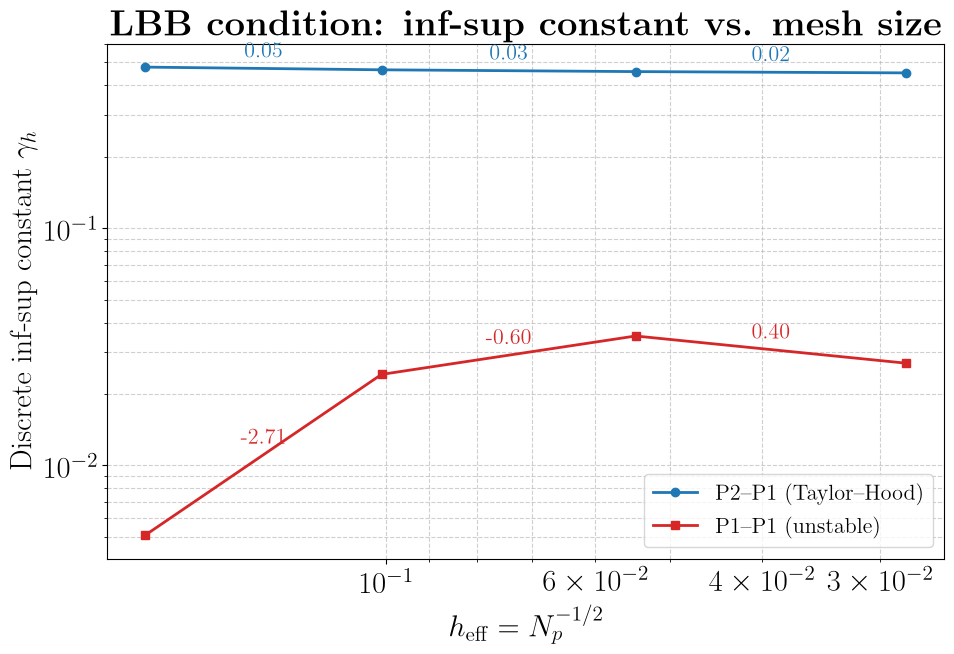

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "font.size": 22,
})

series = {
    (2, 1): (r"P2--P1 (Taylor--Hood)", "tab:blue", "o"),
    (1, 1): (r"P1--P1 (unstable)",     "tab:red",  "s"),
}

plt.figure(figsize=(10, 7))
for key, (label, color, marker) in series.items():
    rows = np.array(results[key], dtype=float)   # columns: n_p, null-space dim, gamma_h
    n_p, gamma = rows[:, 0], rows[:, 2]
    h = n_p ** -0.5                               # mesh-size proxy from the pressure unknowns

    plt.loglog(h, gamma, marker=marker, linestyle="-", color=color, lw=2, label=label)

    # Slope between successive points: how fast gamma_h decays with h
    slopes = np.log(gamma[:-1] / gamma[1:]) / np.log(h[:-1] / h[1:])
    for i, s in enumerate(slopes):
        hm, gm = np.sqrt(h[i] * h[i + 1]), np.sqrt(gamma[i] * gamma[i + 1])
        plt.annotate(f"{s:.2f}", (hm, gm), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=16, color=color)

plt.gca().invert_xaxis()
plt.xlabel(r"$h_\mathrm{eff} = N_p^{-1/2}$")
plt.ylabel(r"Discrete inf-sup constant $\gamma_h$")
plt.title(r"\textbf{LBB condition: inf-sup constant vs. mesh size}")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend(fontsize=16)

plt.tight_layout()
plt.savefig("/home/lukasl/Documents/vienna_uni/computational_analysis_seminar/comp_math_presentation/images/inf_sup_constant.png",
            dpi=300, bbox_inches="tight", transparent=True)
plt.show()